# Phân loại Spam/Ham bằng viBERT



Fine-tune viBERT cho bình luận PTIT, lựa chọn bằng validation và đối chiếu với
TF-IDF + SVM trên cùng tập test. Notebook trình bày dữ liệu, tokenization,
huấn luyện, đánh giá, phân tích lỗi và ứng dụng mô hình đã lưu.


## 1. Cấu hình môi trường

Colab sử dụng GPU và thư viện trong `requirements/modern-colab.txt`; môi trường
local dùng `.venv-modern` và `requirements/modern.txt`. Code, v7 và kết quả S3
được đặt trong cùng project theo hướng dẫn `docs/guides/HUONG_DAN_VIBERT_COLAB.md`.

`MODE="review"` đọc kết quả và checkpoint đã huấn luyện. `MODE="train"` thực
hiện fine-tune, chọn cấu hình, huấn luyện cuối và đánh giá trước khi trình bày.
Các cell đọc bảng/hình không tự huấn luyện lại. Chạy theo thứ tự từ đầu.


In [1]:
import os, sys, json
from pathlib import Path
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "pipeline/modern/train.py").exists()), Path("/content/ptit-facebook-spam-ham"))
if not (PROJECT_ROOT / "pipeline/modern/train.py").exists():
    raise FileNotFoundError("Chuẩn bị gói project theo hướng dẫn viBERT trước khi chạy notebook.")
sys.path.insert(0, str(PROJECT_ROOT))
MODE = "review"
CSV_PATH = Path(os.environ.get("SPAMHAM_CSV", str(PROJECT_ROOT / "data/final/labeled_v7.csv")))
CONFIG_PATH = PROJECT_ROOT / "pipeline/modern/vibert_config.json"
OUTPUT_DIR = Path(os.environ.get("SPAMHAM_VIBERT_OUTPUT", str(PROJECT_ROOT / "artifacts/modern/vibert")))
MODEL_DIR = OUTPUT_DIR / "model"
BASELINE_PREDICTIONS = PROJECT_ROOT / "artifacts/spamham/test_predictions.csv"
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers
from transformers import AutoTokenizer
from IPython.display import Markdown, Image
from pipeline.presentation.notebook_display import display_readable as display, code_excerpt_html
from pipeline.modern.data import prepare_data, split_summary
from pipeline.modern.train import run_experiment
from pipeline.modern.predict import VibertPredictor
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)
print("Thiết bị:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Chế độ:", MODE, "| Kết quả:", OUTPUT_DIR)


C:\KH086\PT&KP DLVB\PROJECT\ptit-facebook-spam-ham\.venv-modern\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.14 | PyTorch: 2.6.0+cpu | Transformers: 4.57.6
Thiết bị: CPU
Chế độ: review | Kết quả: C:\KH086\PT&KP DLVB\PROJECT\ptit-facebook-spam-ham\artifacts\modern\vibert


## 2. Dữ liệu và thiết kế thực nghiệm

Giữ v7 và quy tắc nhóm văn bản của Notebook 02. Tập test gồm cùng 7.474 ID.
Trong train, chọn fold đầu làm validation; các nhóm văn bản không giao nhau.

Huấn luyện phát triển trên 24.815 mẫu, kiểm định trên 5.944 mẫu. Chọn loại loss
và epoch theo **F1 spam trên validation**. Sau đó khởi tạo lại từ viBERT gốc,
huấn luyện cấu hình đã chọn trên toàn bộ 30.759 mẫu train với số epoch đã xác
định; chỉ lúc này mới đánh giá test. Điểm validation không phải CV F1 năm fold.


In [2]:
data = prepare_data(CSV_PATH, CONFIG["validation_fold"])
display(split_summary(data))
preview = data[data.development_split.eq("fit")].groupby("label").sample(n=3, random_state=CONFIG["seed"])
display(preview[["id", "label", "text", "model_text"]])


development_split,ham,spam
fit,21204,3611
validation,5180,764
test,6523,951


#,id,label,text,model_text
10612,cmt_10948,ham,グエン・ヴィエ・ フイ cuối kỳ gánh hết,グエン・ヴィエ・ フイ cuối kỳ gánh hết
28771,cmt_30081,ham,check lịch qlđt em ơi,check lịch qlđt em ơi
29507,cmt_30846,ham,Khương Thị Liên oke mình cảm ơn,Khương Thị Liên oke mình cảm ơn
1323,cmt_1361,spam,Quang Anh Pham .,Quang Anh Pham .
16802,cmt_17697,spam,Đấm Trịnh Trung Anh,Đấm Trịnh Trung Anh
29134,cmt_30458,spam,Bạn inb mình ạ,Bạn inb mình ạ


## 3. Chuẩn hóa và tokenization

Chuẩn hóa Unicode, HTML và khoảng trắng, giữ chữ hoa/thường và từ dừng. Tokenizer
cased của viBERT tách subword, bổ sung token đặc biệt và tạo attention mask.
Padding theo batch, cắt các chuỗi vượt độ dài cấu hình. Bảng token dùng bình luận
trong train; tỷ lệ bị cắt được khảo sát trên train, không dùng test để chọn độ dài.

**Cách đọc bảng token:** đây là các đơn vị WordPiece, không phải câu văn sau
làm sạch để đọc thông thường. `##` đánh dấu phần tiếp nối của một từ, chẳng hạn
`Ph` + `##am`; `[CLS]` đứng đầu chuỗi, `[SEP]` kết thúc chuỗi và `[PAD]` dùng
để đệm các chuỗi trong batch. `[UNK]` là token ngoài khả năng biểu diễn của từ
vựng; đó là mất thông tin ở tokenizer, không phải lỗi font hoặc mã hóa CSV.

Bảng giữ nguyên cả tên riêng, teencode và ký tự nước ngoài từ dữ liệu. Ví dụ
`cmt_10948` có tên bằng tiếng Nhật ngay trong cột `text` của v7. Không sửa tên
hoặc bỏ mẫu chỉ để bảng trông dễ đọc. Số `[UNK]` được đếm trên chuỗi sau cắt;
cột token hiển thị tối đa 24 token đầu, không phải toàn bộ chuỗi của mọi mẫu.


In [3]:
tokenizer_source = MODEL_DIR if MODEL_DIR.exists() else CONFIG["model_name"]
tokenizer = AutoTokenizer.from_pretrained(tokenizer_source,
    **({"local_files_only": True} if MODEL_DIR.exists() else {"revision": CONFIG["revision"], "token": False}),
    do_lower_case=False)
token_rows = []
for row in preview.itertuples():
    ids = tokenizer(row.model_text, truncation=True, max_length=CONFIG["max_length"])["input_ids"]
    token_rows.append({"ID": row.id, "Bình luận": row.model_text, "Số token sau cắt": len(ids),
                       "Số [UNK]": ids.count(tokenizer.unk_token_id),
                       "WordPiece (tối đa 24 token đầu)": " ".join(tokenizer.convert_ids_to_tokens(ids[:24]))})
display(pd.DataFrame(token_rows))
train_text = data.loc[data.outer_split.eq("train"), "model_text"].tolist()
lengths = pd.Series([len(ids) for ids in tokenizer(train_text, truncation=False, verbose=False)["input_ids"]])
display(pd.DataFrame({"Số bình luận train": [len(lengths)], "Giới hạn token": [CONFIG["max_length"]],
                      "Tỷ lệ vượt giới hạn (%)": [round(lengths.gt(CONFIG["max_length"]).mean()*100, 2)]}))


#,ID,Bình luận,Số token sau cắt,Số [UNK],WordPiece (tối đa 24 token đầu)
0,cmt_10948,グエン・ヴィエ・ フイ cuối kỳ gánh hết,12,5,[CLS] [UNK] [UNK] [UNK] [UNK] [UNK] cuối kỳ g ##ánh hết [SEP]
1,cmt_30081,check lịch qlđt em ơi,11,0,[CLS] check lịch q ##l ##đ ##t em ơ ##i [SEP]
2,cmt_30846,Khương Thị Liên oke mình cảm ơn,13,0,[CLS] K ##h ##ương Thị Liên ok ##e mình cảm ơ ##n [SEP]
3,cmt_1361,Quang Anh Pham .,7,0,[CLS] Quang Anh Ph ##am . [SEP]
4,cmt_17697,Đấm Trịnh Trung Anh,7,0,[CLS] Đ ##ấm Trịnh Trung Anh [SEP]
5,cmt_30458,Bạn inb mình ạ,8,0,[CLS] B ##ạn in ##b mình ạ [SEP]


#,Số bình luận train,Giới hạn token,Tỷ lệ vượt giới hạn (%)
0,30759,128,0.77


## 4. Xây dựng mô hình

Sử dụng checkpoint `FPTAI/vibert-base-cased`, bổ sung đầu phân loại hai nhãn:
0 = ham, 1 = spam. Fine-tune cả encoder và đầu phân loại bằng dữ liệu nhóm.
viBERT tạo biểu diễn ngữ cảnh rồi trả logits hai lớp; softmax chuyển thành
xác suất spam. Quy tắc phân loại dùng ngưỡng xác suất 0,5 cố định.

Checkpoint gốc là mô hình tiền huấn luyện, chưa phải bộ phân loại spam PTIT.
Mã nạp kiểm tra trọng số encoder; đầu phân loại được học trong fine-tune.


In [4]:
display(code_excerpt_html(PROJECT_ROOT / "pipeline/modern/train.py", "load_pretrained", max_lines=25))
display(pd.DataFrame([{"Checkpoint": CONFIG["model_name"], "Nhãn": "ham / spam",
                       "Ngưỡng xác suất": CONFIG["threshold"], "Seed": CONFIG["seed"]}]))


'<div class="ptit-code" style="background:#0f172a!important;color:#f1f5f9!important;padding:14px;border:1px solid #475569;border-radius:6px;margin:10px 0;"><div style="background:#0f172a!important;color:#cbd5e1!important;font-size:12px;margin-bottom:10px;">train.py:83 — load_pretrained · 11/11 dòng</div><pre style="background:#0f172a!important;color:#f1f5f9!important;margin:0;white-space:pre-wrap;overflow-wrap:anywhere;font:13px/1.6 Consolas,monospace;"><code style="background:#0f172a!important;color:#f1f5f9!important;">def load_pretrained(config):\n    tokenizer = AutoTokenizer.from_pretrained(config[&quot;model_name&quot;], revision=config[&quot;revision&quot;],\n                                              do_lower_case=False, token=False)\n    model, info = AutoModelForSequenceClassification.from_pretrained(\n        config[&quot;model_name&quot;], revision=config[&quot;revision&quot;], num_labels=2,\n        id2label={0: &quot;ham&quot;, 1: &quot;spam&quot;}, label2id={&quot;ham&

#,Checkpoint,Nhãn,Ngưỡng xác suất,Seed
0,FPTAI/vibert-base-cased,ham / spam,0.5,42


## 5. Huấn luyện và lựa chọn cấu hình

Đối chiếu cross-entropy thông thường và cross-entropy có trọng số lớp. Trọng số
chỉ tính từ phần train đang dùng; validation/test giữ phân bố nhãn tự nhiên.
Đây là khảo sát bổ trợ về mất cân bằng. Learning rate, batch, độ dài và số epoch
được khai báo trong `vibert_config.json`. Mỗi lượt lưu checkpoint theo epoch để
có thể tiếp tục khi runtime ngắt; không resume sang cấu hình hoặc ID khác.

Chọn loss và epoch có validation F1 cao nhất, huấn luyện lại từ checkpoint gốc
trên toàn bộ train. Biểu đồ và bảng bên dưới được đọc từ lịch sử huấn luyện đã
ghi; không dùng chỉ số test để lựa chọn hoặc thay đổi cấu hình.


#,Phiên huấn luyện
Thiết bị huấn luyện,NVIDIA A100-SXM4-80GB
Python huấn luyện,3.13.16
PyTorch huấn luyện,2.11.0+cu130


#,variant,epoch,loss,accuracy,precision,recall,f1,ap
0,unweighted,3,0.2115,0.9558,0.8573,0.7866,0.8205,0.8819
1,balanced,3,0.4392,0.9549,0.8454,0.7945,0.8192,0.8858


#,Cấu hình lựa chọn
variant,unweighted
epoch,3
loss,0.2114548236131668
accuracy,0.9557537012113055
precision,0.8573466476462197
recall,0.7866492146596858
f1,0.8204778156996587
ap,0.8819395039357796


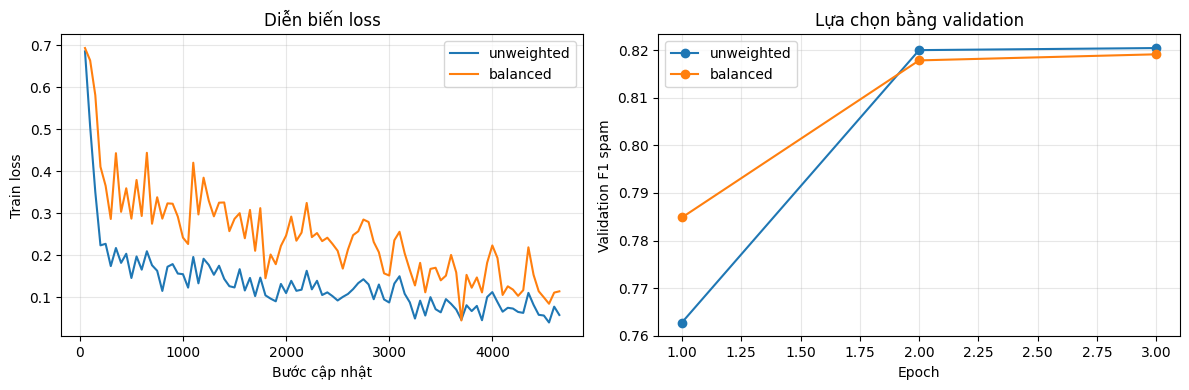

In [5]:
if MODE == "train":
    run_experiment(CSV_PATH, OUTPUT_DIR, BASELINE_PREDICTIONS, CONFIG_PATH, stage="all")
elif MODE != "review":
    raise ValueError("MODE cần là train hoặc review.")
if not (OUTPUT_DIR / "verification.json").exists():
    raise FileNotFoundError("Chưa có lượt huấn luyện hoàn tất. Xem hướng dẫn Colab để chạy và tải kết quả.")
validation = pd.read_csv(OUTPUT_DIR / "validation_metrics.csv")
selected = json.loads((OUTPUT_DIR / "selected.json").read_text(encoding="utf-8"))
training_environment = json.loads((OUTPUT_DIR / "run_config.json").read_text(encoding="utf-8"))
display(pd.Series({"Thiết bị huấn luyện": training_environment["device"], "Python huấn luyện": training_environment["python"], "PyTorch huấn luyện": training_environment["torch"]}, name="Phiên huấn luyện").to_frame())
display(validation.round(4))
display(pd.Series(selected, name="Cấu hình lựa chọn").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for variant in CONFIG["variants"]:
    history = pd.read_csv(OUTPUT_DIR / "selection" / variant / "training_history.csv")
    loss_rows = history.dropna(subset=["loss"])
    validation_rows = history.dropna(subset=["eval_f1"])
    axes[0].plot(loss_rows["step"], loss_rows["loss"], label=variant)
    axes[1].plot(validation_rows["epoch"], validation_rows["eval_f1"], marker="o", label=variant)
axes[0].set(xlabel="Bước cập nhật", ylabel="Train loss", title="Diễn biến loss")
axes[1].set(xlabel="Epoch", ylabel="Validation F1 spam", title="Lựa chọn bằng validation")
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


## 6. Đánh giá và so sánh mô hình

Đo Accuracy, Precision, Recall, F1 spam và AP trên cùng ID test với S3. Bảng này
so sánh hai pipeline hoàn chỉnh, có cách biểu diễn/chuẩn hóa phù hợp từng phương
pháp. Chỉ so sánh các chỉ số test; không đối chiếu validation F1 của viBERT với
CV F1 của SVM như hai phép đo tương đương.

Ma trận nhầm lẫn thể hiện FP/FN. Đường Precision–Recall dùng xác suất viBERT và
decision score SVM để đánh giá khả năng xếp hạng; hai loại score không cùng thang.


#,Mã,Mô hình,Chiến lược,Accuracy,Precision,Recall,F1,AP
0,S3,TF-IDF + SVM,Điều chỉnh ngưỡng,0.9433,0.8374,0.6877,0.7552,0.8117
1,M1,viBERT,unweighted,0.9635,0.8942,0.8086,0.8493,0.9108


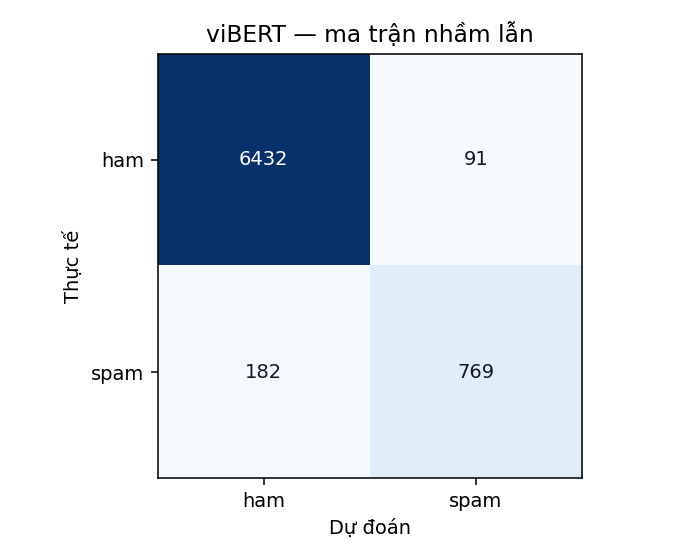

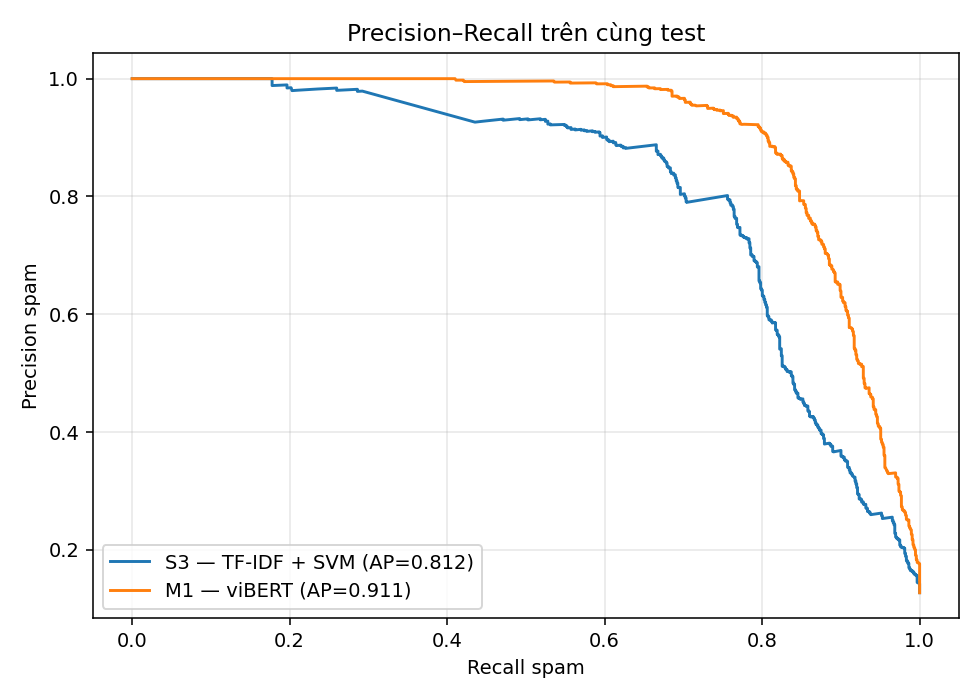

In [6]:
comparison = pd.read_csv(OUTPUT_DIR / "comparison_with_svm.csv")
display(comparison.round(4))
display(Image(filename=str(OUTPUT_DIR / "figures/confusion_vibert.png")))
display(Image(filename=str(OUTPUT_DIR / "figures/pr_comparison.png")))


## 7. Phân tích dự đoán

Phân tích lỗi của **viBERT đã chọn**, dùng ID và bình luận gốc từ test. FP là ham
bị nhận nhầm; FN là spam bị bỏ sót. Xác suất spam là đầu ra mô hình, không phải
bảo đảm độ tin cậy đã hiệu chỉnh. Các ví dụ dùng để giải thích, không tự sửa nhãn.


In [7]:
test_predictions = pd.read_csv(OUTPUT_DIR / "test_predictions.csv", keep_default_na=False, dtype={"id": str})
expected_ids = data.loc[data.outer_split.eq("test"), "id"].tolist()
assert test_predictions.id.tolist() == expected_ids
print("Ham bị nhận nhầm thành spam (FP):")
display(test_predictions[test_predictions.label.eq("ham") & test_predictions.prediction.eq("spam")]
        .sort_values("probability_spam", ascending=False).head(8))
print("Spam bị bỏ sót (FN):")
display(test_predictions[test_predictions.label.eq("spam") & test_predictions.prediction.eq("ham")]
        .sort_values("probability_spam").head(8))


Ham bị nhận nhầm thành spam (FP):


#,id,text,label,prediction,probability_spam
4051,cmt_21698,CalmBlueberry7823 dạ còn ạ ib 0365467168 ạ,ham,spam,0.99947256
3666,cmt_19384,DecisiveOwl9069 0388120543 b ib số này nha,ham,spam,0.9994579
4686,cmt_25167,🌐 Chuyên ngành Thương mại Điện tử: D26CQTM01-B : https://m.me/j/AbY2lWGe8_9tO6hS/ D26CQTM02-B : https://m.me/j/AbZOYYseyk-laqbU/ D26CQTM03-B : https://m.me/j/AbYGu62eciZFmbYF/,ham,spam,0.999071
4624,cmt_24772,Các hình thức học: Trực tiếp: Học trực tiếp tại Hội trường A2 và phòng 101-A2 Online: Học trực tuyến tại địa chỉ: https://live.ptit.edu.vn SHL+LMS: Tham gia sinh hoạt lớp theo lịch + học chuyên đề qua hệ thống LMS: Học chuyên đề qua hệ thống LMS sau đó 1 ngày https://ms.ptit.edu.vn,ham,spam,0.99869555
4793,cmt_25722,Nguyễn Lê Em nhắn page nhen,ham,spam,0.99808455
5634,cmt_30168,pass pldc + mác 100k ib bay nhanh,ham,spam,0.99727964
2704,cmt_14150,TuấnLinh,ham,spam,0.9970131
1781,cmt_9369,"Mình có bạn Dang Viet Anh A+ THHT, sự thật. Bạn liên hệ ngay nhé!!",ham,spam,0.99637127


Spam bị bỏ sót (FN):


#,id,text,label,prediction,probability_spam
4225,cmt_22656,ConfidentDeer6614 mình còn k ạ,spam,ham,0.0005399804
4480,cmt_23939,họp băng đảng b ạ,spam,ham,0.000543152
6436,p2_cmt_1123,VioletMouse3355 shop cảm ơn ạ,spam,ham,0.0005452766
5364,cmt_28711,Nhàn Thanh ngành nào cũm nộp đc đơn phải khơm chị,spam,ham,0.00055385876
5461,cmt_29251,hàng tặng mà đem bán =)),spam,ham,0.0005669857
6105,cmt_32632,có thì cho mình ké,spam,ham,0.0005861161
1770,cmt_9308,Lê Đình Phát toàn đi cắm r,spam,ham,0.0005941797
5573,cmt_29814,Chi Yen có ạ,spam,ham,0.000603531


## 8. Lưu mô hình và dự đoán bình luận mới

`train.py` lưu model và tokenizer bằng `save_pretrained()` vào `model/`. Thư mục
chứa trọng số, cấu hình BERT, ánh xạ nhãn, tokenizer và cấu hình chuẩn hóa/ngưỡng.
Sau huấn luyện, nạp lại và kiểm tra dự đoán trên toàn bộ test trước khi xác nhận
hoàn tất. Demo bên dưới dùng chính thư mục này, không huấn luyện lại.

Bình luận rất ngắn hoặc chỉ có dấu câu thiếu thông tin ngữ nghĩa; mô hình vẫn
có thể trả xác suất cao. Demo phản ánh hành vi hiện tại, không tự sửa dự đoán
theo kỳ vọng. Khi ứng dụng cần xem xét riêng các đầu vào thiếu nội dung.


In [8]:
verification = json.loads((OUTPUT_DIR / "verification.json").read_text(encoding="utf-8"))
display(pd.Series({"Trạng thái": verification["status"], "Số mẫu test": verification["test_rows"],
                   "Nạp lại khớp dự đoán": verification["reload_predictions_match"],
                   "Ngưỡng xác suất": verification["threshold"]}, name="Kiểm tra").to_frame())
predictor = VibertPredictor(MODEL_DIR)
display(predictor.predict(["Cho mình hỏi lịch thi với ạ", "Liên hệ 0901234567 hoặc https://example.com",
                           "Có bạn nào học môn này không?", "."]))


#,Kiểm tra
Trạng thái,completed
Số mẫu test,7474
Nạp lại khớp dự đoán,True
Ngưỡng xác suất,0.5


#,text,probability_spam,du_doan
0,Cho mình hỏi lịch thi với ạ,0.0005634462577290833,ham
1,Liên hệ 0901234567 hoặc https://example.com,0.9993601441383362,spam
2,Có bạn nào học môn này không?,0.0004538267676252872,ham
3,.,0.9996579885482788,spam


## 9. Nhận xét

Nhận xét dựa trên kết quả test đã đo, cùng giới hạn dữ liệu và phạm vi lựa chọn.
Các câu demo minh họa cách sử dụng, không thay thế đánh giá trên test.


In [9]:
modern = comparison[comparison["Mã"].eq("M1")].iloc[0]
svm = comparison[comparison["Mã"].eq("S3")].iloc[0]
fp = int((test_predictions.label.eq("ham") & test_predictions.prediction.eq("spam")).sum())
fn = int((test_predictions.label.eq("spam") & test_predictions.prediction.eq("ham")).sum())
display(Markdown(f"""
- **Lựa chọn:** viBERT với loss `{selected['variant']}`, {selected['epoch']} epoch, chọn bằng validation F1.
- **Test:** Accuracy {modern['Accuracy']:.2%}, Precision {modern['Precision']:.2%},
  Recall {modern['Recall']:.2%}, F1 {modern['F1']:.4f}, AP {modern['AP']:.4f}.
  Có {fp:,} ham bị nhận nhầm và {fn:,} spam bị bỏ sót.
- **Đối chiếu S3:** chênh lệch F1 = {modern['F1']-svm['F1']:+.4f}; đọc cùng Precision/Recall và loại lỗi.
- **Giới hạn:** kết quả phụ thuộc nhãn hiện có, dữ liệu gần trùng, bình luận ngắn và ngữ cảnh bài đăng.
  Chưa khảo sát nhiều seed hoặc mọi cấu hình; không khẳng định một mô hình luôn tốt hơn.
- **Ứng dụng:** checkpoint đã lưu dùng để nạp lại và phân loại bình luận mới bằng cùng tokenizer/ngưỡng.
"""))



- **Lựa chọn:** viBERT với loss `unweighted`, 3 epoch, chọn bằng validation F1.
- **Test:** Accuracy 96.35%, Precision 89.42%,
  Recall 80.86%, F1 0.8493, AP 0.9108.
  Có 91 ham bị nhận nhầm và 182 spam bị bỏ sót.
- **Đối chiếu S3:** chênh lệch F1 = +0.0941; đọc cùng Precision/Recall và loại lỗi.
- **Giới hạn:** kết quả phụ thuộc nhãn hiện có, dữ liệu gần trùng, bình luận ngắn và ngữ cảnh bài đăng.
  Chưa khảo sát nhiều seed hoặc mọi cấu hình; không khẳng định một mô hình luôn tốt hơn.
- **Ứng dụng:** checkpoint đã lưu dùng để nạp lại và phân loại bình luận mới bằng cùng tokenizer/ngưỡng.


## Tài liệu tham khảo

- viBERT: https://github.com/fpt-corp/viBERT
- Checkpoint: https://huggingface.co/FPTAI/vibert-base-cased
- Transformers — text classification: https://huggingface.co/docs/transformers/tasks/sequence_classification
- PyTorch — CrossEntropyLoss: https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- Dataset PTIT: https://huggingface.co/datasets/p-storm/ptit-facebook-comments-spamham
- Tokenizer BERT và token đặc biệt: https://huggingface.co/docs/transformers/model_doc/bert#berttokenizer
